# Import libraries

In [1]:
# General libraries
import numpy as np
import pandas as pd
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

# Plotting libraries
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

# Module
import ximinf.nn_inference as nninf
import ximinf.nn_train as nntr
import ximinf.nn_test as nnte
import ximinf.nn_io as nnio
import ximinf.cosmo_helper as ch
import ximinf.data_helper as dh
import ximinf.plots as plt_tools
plt_tools.apply_default_settings()
%matplotlib inline 

from source import inference_file_path
from source import nn_path

# nn_path = "../data/NNs/nn_model_priors_uniform_M_N_200000_1_M_1000_batch_500_lr_1e-4_mabs_beta_alpha_gamma_dropout_0_0_phi_0_2_rho_deepset_256_depth_1_patience_10_proxies_with_z"

sim_config_temp = dh.load_module_from_run(nn_path, module_filename="sim_config.py")
nn_config_temp = dh.load_module_from_run(nn_path, module_filename="nn_config.py")

get_quality_mask = sim_config_temp.get_quality_mask

DeepSetClassifier = nn_config_temp.DeepSetClassifier

cosmo = ch.get_canonical("PlanckBAO18")
cosmologix_cosmo = ch.to_cosmologix(cosmo)

# Jax libraries
import jax.numpy as jnp
import jax

# Warning management
from absl import logging
logging.set_verbosity(logging.ERROR)

In [2]:
print(cosmologix_cosmo)

{'Tcmb': Array(2.7255, dtype=float32, weak_type=True), 'Omega_bc': Array(0.30964145, dtype=float32, weak_type=True), 'H0': Array(67.66, dtype=float32, weak_type=True), 'Omega_b_h2': Array(0.02242, dtype=float32, weak_type=True), 'Omega_k': Array(0., dtype=float32, weak_type=True), 'w': Array(-1., dtype=float32, weak_type=True), 'wa': Array(0., dtype=float32, weak_type=True), 'm_nu': Array(0.06, dtype=float32, weak_type=True), 'Neff': Array(3.046, dtype=float32, weak_type=True)}


# Load NN

In [3]:
# Parameters
models_per_group, models_config = nnio.load_autoregressive_nn(nn_path, DeepSetClassifier)


# Set device type

In [4]:
key = jax.random.PRNGKey(42)

In [5]:
device, backend, cpu, gpu = nntr.setup_jax_device()

gpu


# Load data

In [6]:
columns = models_config['shared']['columns']
# if 'z' not in columns:
#     columns = columns + ['z']

params, data_dict = dh.load_hdf5(inference_file_path)

In [7]:
columns

['magobs', 'magobs_err', 'x1', 'x1_err', 'c', 'c_err', 'z']

In [8]:
data_dict['z'][0:10]

Array([0.04435, 0.02955, 0.04595, 0.03255, 0.05185, 0.04965, 0.05875,
       0.03595, 0.05935, 0.05895], dtype=float32)

In [9]:
inputs_infer, data_dict, mask, max_size = dh.process_simulation_results(data_dict, columns, models_config, get_quality_mask, cosmologix_cosmo, disable_x64_after=True) #dh.

The compilation cache as grown to 2.12 GB.Caching is disabled for now.Clear the cache using `cosmologix clear-cache -j` to re-enable.Or directly from python: tools.clear_cache(jit=True)


In [10]:
# columns = [col for col in columns if col != 'z']

In [11]:
# columns

In [12]:
print(f'Sample size : {jnp.sum(mask)}')

Sample size : 1000


# MCMC

## Set priors

In [13]:
priors = models_config['shared']['priors']

# Change the priors here if needed

# if 'mabs' in priors:
#     priors['mabs']['range'] += 19.3

In [14]:
priors

{'alpha': {'range': array([-0.17882457, -0.14317542], dtype=float32),
  'type': 'uniform'},
 'beta': {'range': array([2.8717544, 3.2282457], dtype=float32),
  'type': 'uniform'},
 'mabs': {'range': array([-0.03087425,  0.03087234], dtype=float32),
  'type': 'uniform'}}

In [15]:
for model_g in models_per_group:
    model_g.eval()  # disable dropout, etc.

global_param_names = models_config['shared']['global_param_names']
print(f"Parameters : {global_param_names}")

param_groups = models_config['shared']['param_groups']

Parameters : ['mabs', 'beta', 'alpha']


In [16]:
param_stats = models_config['shared']['param_stats']

normalized_priors = {}

for name, prior in priors.items():
    mu = param_stats[name]['mu']
    sigma = param_stats[name]['sigma']

    norm_range = (prior['range'] - mu) / sigma
        
    normalized_priors[name] = {
        'range': norm_range,
        'type': prior['type']  # type stays unchanged
    }


theta_init_dict = {
    name: 0.5 * (priors[name]['range'][0] + 
                 priors[name]['range'][1])
    for name in global_param_names
}

theta_init_normed_dict = {
    name: (
        theta_init_dict[name] - param_stats[name]['mu']
    ) / param_stats[name]['sigma']
    for name in global_param_names
}

theta_init_normed = jnp.array(
    [theta_init_normed_dict[name] for name in global_param_names]
)

## Launch MCMC

In [17]:
# ========== MCMC Sampling ==========

# ----------------------------
# Precompute parameter indices
# ----------------------------

group_names_list = []
for g in param_groups:
    if isinstance(g, str):
        group_names_list.append([g])  # wrap single parameter in a list
    else:
        group_names_list.append(g)  
        
visible_indices, group_indices = nninf.preprocess_groups(param_groups, global_param_names)

n_points = 2000

print("Launch MCMC ...")

def log_post(theta):
    # Use the new grouped log-prob function
    return nninf.log_prob_fn_groups(
        theta,
        models_per_group,  # list of models per group
        inputs_infer,
        normalized_priors,
        visible_indices,
        group_indices,
        group_names_list
    )

# Run MCMC
key, post = nninf.sample_posterior(
    log_post,
    n_warmup=200,
    n_samples=n_points,
    init_position=theta_init_normed,
    rng_key=key
)

print("...finished")

Launch MCMC ...
...finished


In [18]:
n_samples, n_params = post.shape

# Convert post from array to dict with column names
post_dict = {name: post[:, i] for i, name in enumerate(global_param_names)}

# Unnormalize each parameter
post_unnormed_dict = dh.unnormalize(post_dict, param_stats)

# Convert back to array for plotting
post_unnormed = jnp.stack([post_unnormed_dict[name] for name in global_param_names], axis=1)

ranges_from_priors = [
    (float(priors[name]['range'][0]), float(priors[name]['range'][1]))
    for name in global_param_names
]

## Corner plot

Removed no burn in


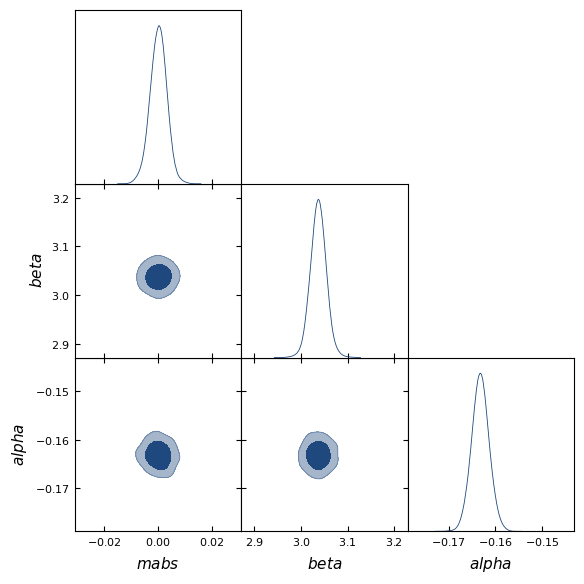

In [19]:
samples = np.array(post_unnormed)

gdsamples = MCSamples(
    samples=samples,
    names=global_param_names,
    labels=global_param_names,
)

g = plots.get_subplot_plotter()

g.triangle_plot(
    gdsamples,
    filled=True,
    contour_colors=["#1F487E"],
    param_limits={
        name: r for name, r in zip(global_param_names, ranges_from_priors)
    }
)

g.export("./corner.png")
plt.show()

In [20]:
np.save("../data/results/sbi_posterior_dict.npy", {
    "offset": post_unnormed[:, global_param_names.index("mabs")],
    # "alpha_low": post_unnormed[:, global_param_names.index("alpha_low")],
    # "alpha_high": post_unnormed[:, global_param_names.index("alpha_high")],
    "alpha": post_unnormed[:, global_param_names.index("alpha")],
    # "x1_ref": post_unnormed[:, global_param_names.index("x1_ref")],
    "beta": post_unnormed[:, global_param_names.index("beta")],
    # "gamma": post_unnormed[:, global_param_names.index("gamma")],
    # "sigma_int": post_unnormed[:, global_param_names.index("sigma_int")]
    })

# Tests

## MCMC chains

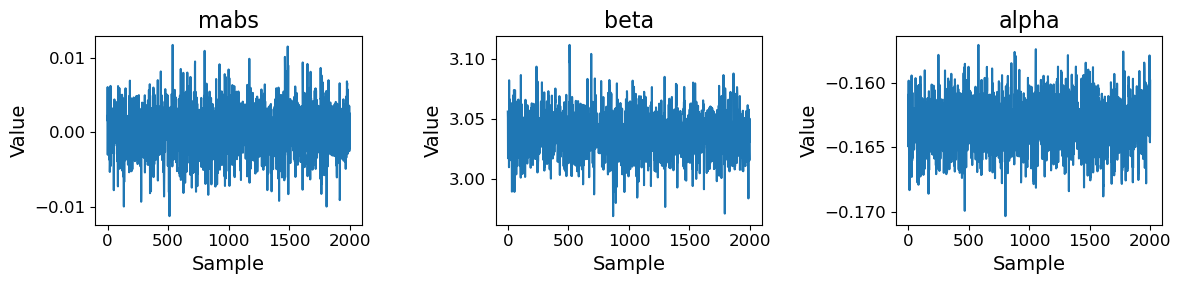

In [21]:
n_cols = len(columns)
n_rows = int(jnp.ceil(n_params / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4 * n_cols, 3 * n_rows),
    squeeze=False
)

axes = axes.flatten()

for i in range(n_params):

    axes[i].plot(post_unnormed[:, i])

    axes[i].set_title(global_param_names[i])

    axes[i].set_xlabel("Sample")

    axes[i].set_ylabel("Value")

# Remove unused subplots
for i in range(n_params, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

## Autocorrelation

In [22]:
arr = nnte.autocorr_fft(post_unnormed[:, global_param_names.index("alpha")], 10)

df = pd.DataFrame({
    "Index": np.arange(len(arr)),
    "Value (%)": arr * 100,
})

print(df.to_string(index=False, formatters={"Value (%)": "{:.3f}%".format}))

 Index Value (%)
     0  100.000%
     1    9.584%
     2   -0.407%
     3   -0.296%
     4   -0.225%
     5    4.624%
     6    2.109%
     7    2.668%
     8   -2.375%
     9    1.258%
